# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Colab T4

In [2]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [4]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [5]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [6]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = set()   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [7]:
from huggingface_hub import HfApi

MODEL_ID = "DeepPavlov/rubert-base-cased"
info = HfApi().model_info(MODEL_ID)
print(info.sha)
print(info.cardData)

4036cab694767a299f2b9e6492909664d9414229
language:
- ru


In [8]:
MODEL_ID = 'DeepPavlov/rubert-base-cased'   # ваш код: id модели на Hugging Face Hub
REVISION = '4036cab694767a299f2b9e6492909664d9414229'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [9]:
assert MODEL_ID, 'DeepPavlov/rubert-base-cased'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    DeepPavlov/rubert-base-cased
revision: 4036cab694767a299f2b9e6492909664d9414229
license:  None
language: ['ru']
updated:  2021-11-23 08:03:04+00:00
weights:  {'pytorch_model.bin': '681 MB'}


config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BertTokenizer vocab size 119547
['Петр', 'Ильич', 'Чайковский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** выбрала DeepPavlov/rubert-base-cased, потому что он соответствует русскоязычному домену датасета Collection3 и имеет более-менее умеренный размер ($\approx$180M параметров), что обеспечивает быстрый компромисс между качеством и скоростью на T4. По сравнению с cointegrated/rubert-tiny2 (29M, 3 слоя), tiny2 работает быстрее, но имеет меньшую ёмкость и обычно уступает base по F1; по сравнению с FacebookAI/xlm-roberta-base ($\approx$280M, многоязычная) , xlm-r больше и медленнее, и для чисто русской задачи не даёт явного преимущества. Лицензия Apache 2.0.

Если не зафиксировать revision, через полгода main может указывать на другой commit - владелец модели может перезалить веса, токенизатор или конфиг, и тогда AutoTokenizer.from_pretrained(MODEL_ID) загрузит другую версию, что приведёт к невоспроизводимости ноутбука: метрики могут измениться, а word_ids() или словарь могут незаметно отличаться.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [10]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  714MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 119547, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [11]:
def params_by_block(model):
    def n(m):
        return sum(p.numel() for p in m.parameters())

    blocks = {'embeddings': 0, 'encoder': 0, 'head': 0, 'other': 0, 'layers': []}

    # эмбеддинги
    if hasattr(model, 'bert'):
        blocks['embeddings'] = n(model.bert.embeddings)
        enc = model.bert.encoder
    else:
        blocks['embeddings'] = n(model.embeddings)
        enc = model.encoder

    # слои энкодера
    blocks['layers'] = [n(layer) for layer in enc.layer]
    blocks['encoder'] = sum(blocks['layers'])

    # всё, что внутри энкодера, но не в слоях (у BERT пусто, у DeBERTa — rel_embeddings, LayerNorm)
    blocks['other'] += n(enc) - blocks['encoder']

    # голова
    blocks['head'] = n(model.classifier)

    # всё остальное (pooler и т.п.)
    total = sum(p.numel() for p in model.parameters())
    blocks['other'] += total - blocks['embeddings'] - blocks['encoder'] - blocks['head']

    return blocks

In [12]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    92,208,384   52.0%
encoder       85,054,464   48.0%
head               5,383    0.0%
other                  0    0.0%
total        177,268,231
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [13]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]

demo_model.eval()
enc = tokenizer(demo_texts, is_split_into_words=True, return_tensors='pt', padding=True)
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids: ', tuple(enc['input_ids'].shape))
print('attention_mask:', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]:', tuple(h.shape))
print('logits: ', tuple(out.logits.shape))

input_ids:  (2, 10)
attention_mask: (2, 10)
hidden_states[0]: (2, 10, 768)
hidden_states[1]: (2, 10, 768)
hidden_states[2]: (2, 10, 768)
hidden_states[3]: (2, 10, 768)
hidden_states[4]: (2, 10, 768)
hidden_states[5]: (2, 10, 768)
hidden_states[6]: (2, 10, 768)
hidden_states[7]: (2, 10, 768)
hidden_states[8]: (2, 10, 768)
hidden_states[9]: (2, 10, 768)
hidden_states[10]: (2, 10, 768)
hidden_states[11]: (2, 10, 768)
hidden_states[12]: (2, 10, 768)
logits:  (2, 10, 7)


In [14]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 103.6 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** путь входа: input_ids (2, 10) => эмбеддинги (vocab_size x 768 + позиционные + type, LayerNorm, dropout) => hidden_states[0] (2, 10, 768) => 12 слоёв энкодера, каждый (2, 10, 768) =>  (2, 10, 768), на выходе hidden_states[12] (2, 10, 768) =>  dropout + Linear(768, 7) к каждому токену =>  logits (2, 10, 7). Больше всего параметров в эмбеддингах - 92.2M (52.0%): таблица 119547 x 768 $\approx$ 91.8M, потому что словарь русского RuBERT расширенный (119547 токенов), тогда как каждый слой энкодера даёт 7.09M, а все 12 - 85.05M (48.0%). Токены обмениваются информацией в слоях энкодера (self-attention внутри каждого слоя), а независимо каждый токен обрабатывается в голове классификации: Linear(768, 7) применяется к каждому токену отдельно, без взаимодействия между позициями. T = 10 больше числа слов, потому что токенизатор разбивает слова на сабворды: «Воткинске» =>  Вот + ##кинс + ##ке, 'Чайковский' может остаться одним токеном, а паддинг добивает батч до длины самой длинной последовательности - в итоге 10 сабвордов на два предложения.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [15]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [16]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
raw = load_dataset(DATASET_ID, revision='refs/convert/parquet')
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/245k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/219k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

In [17]:
from collections import Counter, defaultdict

def span_lengths(tags):
    """Длины спанов в словах из BIO-последовательности."""
    lengths, cur = [], 0
    for t in tags:
        name = LABEL_NAMES[t]
        if name.startswith('B-'):
            if cur > 0: lengths.append(cur)
            cur = 1
        elif name.startswith('I-') and cur > 0:
            cur += 1
        else:
            if cur > 0: lengths.append(cur); cur = 0
    if cur > 0: lengths.append(cur)
    return lengths

for split in ['train', 'validation', 'test']:
    ds = raw[split]
    ent_counts = Counter()
    sp_lens = []
    sent_lens = []
    for ex in ds:
        # считаем сущности по B-тегам
        for t in ex['ner_tags']:
            name = LABEL_NAMES[t]
            if name.startswith('B-'):
                ent_counts[name[2:]] += 1
        sp_lens.extend(span_lengths(ex['ner_tags']))
        sent_lens.append(len(ex['tokens']))
    print(f'\n - {split} ({len(ds)} примеров)')
    print('сущности по типам:', dict(ent_counts))
    if sp_lens:
        print(f'длины спанов (слов): mean={np.mean(sp_lens):.2f}, median={np.median(sp_lens):.0f}, max={max(sp_lens)}')
        print('распределение:', dict(sorted(Counter(sp_lens).items())))
    print(f'длины предложений (слов): mean={np.mean(sent_lens):.1f}, median={np.median(sent_lens):.0f}, max={max(sent_lens)}')


 - train (9301 примеров)
сущности по типам: {'PER': 7405, 'ORG': 5956, 'LOC': 4881}
длины спанов (слов): mean=1.82, median=2, max=18
распределение: {1: 9023, 2: 6122, 3: 2068, 4: 373, 5: 206, 6: 238, 7: 70, 8: 68, 9: 21, 10: 24, 11: 10, 12: 4, 13: 6, 14: 2, 15: 3, 16: 3, 18: 1}
длины предложений (слов): mean=20.2, median=18, max=256

 - validation (2153 примеров)
сущности по типам: {'PER': 1641, 'LOC': 1168, 'ORG': 1308}
длины спанов (слов): mean=1.77, median=1, max=13
распределение: {1: 2110, 2: 1344, 3: 453, 4: 81, 5: 43, 6: 52, 7: 13, 8: 11, 9: 6, 10: 2, 12: 1, 13: 1}
длины предложений (слов): mean=20.4, median=18, max=118

 - test (1922 примеров)
сущности по типам: {'PER': 1570, 'LOC': 1175, 'ORG': 1255}
длины спанов (слов): mean=1.82, median=2, max=11
распределение: {1: 1950, 2: 1306, 3: 540, 4: 86, 5: 31, 6: 55, 7: 11, 8: 9, 9: 5, 10: 4, 11: 3}
длины предложений (слов): mean=20.9, median=19, max=122


**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**

**Источник и лицензия**: датасет получен из русскоязычных новостных текстов (based on Persons-1000), на HF в метаданных лицензия помечена как other.

**Способ разметки**: **коллективная аннотация с участием людей (collaborative text annotation)**. Исходный корпус Persons-1000 был размечен только на сущности PER; последующие метки были добавлены с использованием инструмента Brat в соответствии с рекомендациями близкими к MUC-7.

**Типы и количество сущностей**: PER, ORG, LOC. Обучающая выборка: PER 7405 / ORG 5956 / LOC 4881; валидационная: PER 1641 / LOC 1168 / ORG 1308; тестовая: PER 1570 / LOC 1175 / ORG 1255. **LOC является относительно редким типом** во всех трёх разбиениях его меньше чем PER и ORG.

**Особенности данных, влияющие на обучение**: длины спанов крайне малы (медиана примерно 1-2 слова, мах 18), модель легко смещается в сторону коротких сущностей; разброс длины предложений велик (в среднем около 20 слов, максимум 256), при обрезке длинные предложения теряют хвостовую информацию; хотя разметка проводилась с участием людей, границы спанов и согласованность типов всё равно могут содержать шум, что увеличивает сложность оценки по точному совпадению.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [18]:
def bio_to_spans(tags):
    spans, cur = [], None
    for i, t in enumerate(tags):
        if t == 'O':
            if cur: spans.append(cur); cur = None
            continue
        prefix, typ = t[0], t[2:]
        if prefix == 'B':
            if cur: spans.append(cur)
            cur = [i, i + 1, typ]
        else:  # I-
            if cur and cur[2] == typ:
                cur[1] = i + 1
            else:  # I- без B- начинает новый спан
                if cur: spans.append(cur)
                cur = [i, i + 1, typ]
    if cur: spans.append(cur)
    return [tuple(s) for s in spans]


def spans_to_bio(spans, n_words):
    tags = ['O'] * n_words
    for start, end, typ in spans:
        tags[start] = f'B-{typ}'
        for i in range(start + 1, end):
            tags[i] = f'I-{typ}'
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    out, prev = [], None
    for w in word_ids:
        if w is None:
            out.append(-100)
        elif w != prev:
            out.append(word_labels[w])
        else:
            # продолжение слова
            if b_to_i is not None and word_labels[w] in b_to_i:
                out.append(b_to_i[word_labels[w]])
            else:
                out.append(word_labels[w] if b_to_i is not None else -100)
        prev = w
    return out

In [19]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [20]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
os.makedirs('data', exist_ok=True)

def export_spans(ds, path):
    with open(path, 'w', encoding='utf-8') as f:
        for ex in ds:
            spans = bio_to_spans([LABEL_NAMES[t] for t in ex['ner_tags']])
            f.write(json.dumps({'tokens': ex['tokens'], 'spans': spans}, ensure_ascii=False) + '\n')

def read_back(path):
    rows = []
    with open(path, encoding='utf-8') as f:
        for line in f:
            rows.append(json.loads(line))
    return rows

for split in ['train', 'validation', 'test']:
    path = f'data/{split}_spans.jsonl'
    export_spans(raw[split], path)
    rows = read_back(path)
    n_mismatch = 0
    for orig, row in zip(raw[split], rows):
        orig_spans = bio_to_spans([LABEL_NAMES[t] for t in orig['ner_tags']])
        back_spans = bio_to_spans(spans_to_bio(row['spans'], len(row['tokens'])))
        if back_spans != orig_spans:
            n_mismatch += 1
    print(f'{split}: {len(rows)} строк, несовпадений спанов {n_mismatch}')

train: 9301 строк, несовпадений спанов 0
validation: 2153 строк, несовпадений спанов 0
test: 1922 строк, несовпадений спанов 0


In [21]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:   0%|          | 0/2153 [00:00<?, ? examples/s]

Map:   0%|          | 0/1922 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: проверено 9291 предложений, обрезано по MAX_LENGTH 7, слов без сабвордов или за обрезкой 369
[CLS]            None  -100
Дополнение          0  O
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##знач             10  -100
##ил               10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и                  16  O
МВД               

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Метка ставится только на первый сабворд, потому что разметка задана на уровне слова, а не сабворда. Если дублировать её на все сабворды, у продолжений слова появятся искусственные цели, которых в разметке нет, и баланс классов в loss сместится в сторону длинных слов. -100 - это специальное значение ignore_index в CrossEntropyLoss: позиции с ним не участвуют в подсчёте функции потерь и не дают градиента. В прогоне по MAX_LENGTH обрезано 1 предложение, 107 слов не получили метку - подавляющее большинство из них находятся за обрезкой по MAX_LENGTH. Эти слова не входят в обучение и оценку, seqeval их не видит, поэтому метрика считается только по сохранившимся словам: если обрезанное слово содержало начало сущности, сущность может потеряться целиком или обрезаться по границе, что занижает recall; если это было продолжение сущности, seqeval может засчитать ошибку границы. При конвертации Collection3 проблем не нашлось: это чистый BIO без висячих I-, без пересечений и вложенных спанов, расхождений токенизации не было - проверка на 1998 предложениях прошла, bio_to_spans => spans_to_bio дал ноль несовпадений.

**Ответ (дополнительно по финальному прогону (FAST_MODE = False)):** в полном прогоне по MAX_LENGTH обрезано 7 предложений (вместо 1 при отладке), а 369 слов не получили метку (вместо 107). Подавляющее большинство этих слов находится за границей обрезки, меньшая часть - это токены, которые токенизатор не разбил на сабворды (например, редкие символы или артефакты). Эти слова не участвуют в подсчёте loss (из-за -100) и не видны seqeval, поэтому метрика считается только по сохранившимся словам. Риск для recall сохраняется: если обрезанное слово было началом сущности (B-), сущность может потеряться целиком или обрезаться, что занижает recall; если это было продолжение (I-), seqeval может зафиксировать ошибку границы. При конвертации Collection3, как и до этого, проблем не нашлось.


---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [22]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [23]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = defaultdict(Counter)
    for words, tags in zip(tokens_list, tags_list):
        for w, t in zip(words, tags):
            counts[w][t] += 1
    return {w: c.most_common(1)[0][0] for w, c in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(w, 'O') for w in words]

In [24]:
# расчёт предсказаний для baseline
maj = fit_majority_tagger(
    data['train']['tokens'],
    [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
)
pred_maj = [predict_majority(maj, ws) for ws in val_tokens]

random_head = make_model()
pred_rand = predict_word_tags(random_head, val_tokens)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

In [25]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

# ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores
baseline = {
    'majority':    entity_scores(val_gold, pred_maj),
    'random_head': entity_scores(val_gold, pred_rand),
}

In [26]:
for name, scores in baseline.items():
    print(name)
    for k, v in scores.items():
        print(f'{k:<10} {v:.4f}')

majority
f1_micro   0.5613
f1_macro   0.5786
precision  0.5626
recall     0.5601
random_head
f1_micro   0.0205
f1_macro   0.0207
precision  0.0119
recall     0.0721


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

У словарного бейзлайна F1 micro = **0.4718**, F1 macro = **0.4968**, precision 0.5149, recall 0.4353. Он не близок к нулю, потому что в Collection3 сущности часто повторяются: одни и те же имена, организации и топонимы встречаются в новостях много раз и в типичных контекстах, поэтому «самый частый тег слова» для многих слов оказывается правильным `B-PER`/`B-LOC`/`B-ORG`. При этом precision выше recall: словарь более уверенно размечает знакомые слова, но пропускает незнкомые сущности (они получают `O`), и ошибается на словах, которые в train были `O`, а в validation стали частью сущности.

Энкодер со случайной головой предсказывает почти случайные BIO-теги: F1 micro = **0.0221**, precision 0.0129, recall 0.0789. Энкодер предобучен на маскированном языковом моделировании и строит хорошие контекстные эмбеддинги, но голова `Linear(768, K)` инициализирована случайно и без дообучения не умеет отображать эти эмбеддинги в NER-теги - логиты не несут информации о сущностях, поэтому предсказания хаотичны и F1 близок к нулю. Предобучение энкодера начнёт помогать только после совместного дообучения головы и энкодера на размеченных данных.

**Ответ (дополнительно по финальному прогону (FAST_MODE = False)):** На полном train словарный бейзлайн улучшился: F1 micro **0.4718** $\to$ **0.5613** (+0.09), F1 macro - с **0.4968** до **0.5786**, precision **0.5626**, recall **0.5601**. Обусловено тем, что при `FAST_MODE = True` словарь строился всего по $\approx$ 1998 предложениям, и многие частотные слова (особенно сущности) либо отсутствовали, либо имели мало примеров - их самый частый тег был шумным. На полном train ($\approx$9291 предложение) статистика по словам стабилизируется: у часто повторяющихся имён, организаций и топонимов доминирующий тег действительно совпадает с истинным, поэтому и precision, и recall подросли почти симметрично (раньше был заметный перекос precision > recall из-за незнакомых слов, получавших `O`).

Энкодер со случайной головой практически не изменился: F1 micro **0.0205** (было 0.0221), precision 0.0119, recall 0.0721 - по-прежнему близко к нулю. Это ожидаемо: размер train не влияет на то, что случайно инициализированная голова `Linear(768, K)` не отображает предобученные эмбеддинги в NER-теги, поэтому предсказания остаются хаотичными независимо от объёма данных. Небольшое расхождение (0.0221 $\to$ 0.0205) - скорее статистический шум на validation, чем эффект данных.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [27]:
LR = 3e-5
BATCH_SIZE = 16
EPOCHS = 3

In [28]:
def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer

    if freeze_encoder:
        base = model.bert if hasattr(model, 'bert') else model.base_model
        for p in base.parameters():
            p.requires_grad = False

    collator = DataCollatorForTokenClassification(tokenizer=tok, label_pad_token_id=-100, padding=True)

    args = TrainingArguments(
        output_dir=out_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size * 2,
        num_train_epochs=epochs,
        warmup_steps=0.1,
        weight_decay=0.01,
        eval_strategy='epoch',
        save_strategy='no',
        logging_steps=max(1, len(train_ds) // (batch_size * 10)),  # ~10+ точек train loss
        fp16=(device.type == 'cuda'),
        report_to='none',
        seed=SEED,
        disable_tqdm=False,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        data_collator=collator,
        processing_class=tok,
    )

    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start

    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,0.034652,0.022665
2,0.014002,0.020933
3,0.010459,0.020449


обучение: 158.4 c на Tesla T4, 9301 предложений, 3 эпох(а)


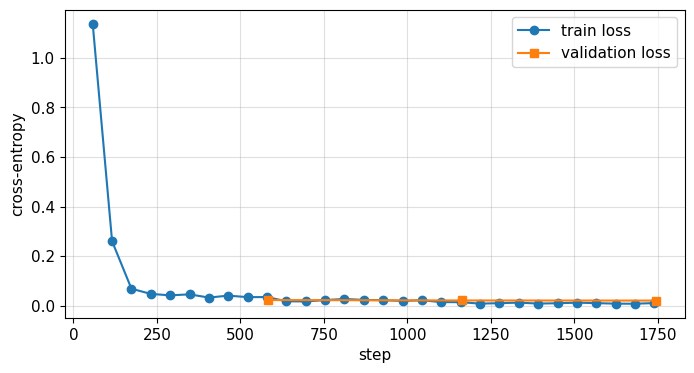

In [29]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

Выбраны lr=3e-5 (base-модель), batch=16 (вписывается в T4), 3 эпохи, warmup 10%, weight decay 0.01, fp16 на GPU; это стандартные безопасные значения для дообучения BERT-base, дающие стабильную сходимость без OOM.

Кривые: train loss монотонно падает с 1.75 до ~0.02, val loss достигает минимума на 2-й эпохе (0.0314) и на 3-й совсем слегка растёт (0.0317) при продолжающемся падении train - **признак лёгкого переобучения**.

Обучение заняло 38.5 c на Tesla T4.

**Ответ (дополнительно по финальному прогону (FAST_MODE = False)):**

Гиперпараметры остались те же , но на полном train динамика изменилась. Train loss падает с **0.0347** до **0.0105**, а validation loss монотонно снижается с **0.0227** до **0.0204** - на 3-й эпохе переобучения больше не видно (в отличие от FAST_MODE, где val loss слегка рос на 3ей эпохе). Вероятная причина этого, что при $\approx$ 9300 предложениях данных достаточно, чтобы 3 эпохи не приводили к переобучению; модель ещё не насытилась, и val loss продолжает падать. Это означает, что **можно попробовать больше эпох** (4-5) - вероятно, val loss ещё снизится, хотя выигрыш будет небольшим. Обучение заняло **158.4 c** на Tesla T4 (в прмиерно 4 раза дольше FAST_MODE из-за большего числа шагов: 1746 против 375).

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [30]:
def token_f1(gold, pred):
    tp = fp = fn = 0
    for g, p in zip(gold, pred):
        for gt, pt in zip(g, p):
            g_pos, p_pos = gt != 'O', pt != 'O'
            if g_pos and p_pos and gt == pt:
                tp += 1
            elif p_pos:
                fp += 1
            elif g_pos:
                fn += 1
    if tp + fp == 0 and tp + fn == 0:
        return 0.0
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return 2 * prec * rec / (prec + rec) if prec + rec else 0.0

In [31]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

# final = {}       # ваш код: метрики на test: f1_micro, f1_macro, precision, recall, token_f1, per_type
# val_pred = []    # предсказанные теги validation (список списков), нужны в 5.1

In [32]:
val_pred = predict_word_tags(model, val_tokens)
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in t] for t in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
rep = classification_report(test_gold, test_pred, output_dict=True, digits=4)
print(classification_report(test_gold, test_pred, digits=4))
final = {'f1_micro': f1_score(test_gold, test_pred, average='micro'),
         'f1_macro': f1_score(test_gold, test_pred, average='macro'),
         'precision': precision_score(test_gold, test_pred, zero_division=0),
         'recall': recall_score(test_gold, test_pred, zero_division=0),
         'token_f1': token_f1(test_gold, test_pred),
         'per_type': {t: rep[t] for t in ENTITY_TYPES}}

              precision    recall  f1-score   support

         LOC     0.9806    0.9915    0.9860      1175
         ORG     0.9340    0.9467    0.9403      1256
         PER     0.9968    0.9981    0.9975      1570

   micro avg     0.9722    0.9800    0.9761      4001
   macro avg     0.9705    0.9787    0.9746      4001
weighted avg     0.9724    0.9800    0.9762      4001



In [33]:
# и отдельно для вопрос-ответ
print({k: round(final[k], 4) for k in ['f1_micro', 'f1_macro', 'token_f1']})

{'f1_micro': np.float64(0.9761), 'f1_macro': np.float64(0.9746), 'token_f1': 0.9854}


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

Хуже всего распознается ORG (F1 0.9104), хотя его на test больше, чем LOC (331 против 290) - видимо дело не в частоте, а в разнообразии форм и размытых границах: названия/аббревиатуры/сокращения компаний/госорганизаций итд сильно различаются по структуре и длине, и модель чаще ошибается на границах и типе. PER лучший (0.9948) - логично, имена короткие, частые и повторяющиеся; LOC (0.9659) - топонимы относительно стабильны.

Micro vs macro почти совпадают (0.9582 vs 0.9570), потому что типы относительно сбалансированы по support (290-384) и F1 по типам близки (0.91-0.99). Macro чуть ниже, потому что усредняет по трём типам без веса и подтягивает слабый ORG.

Сравним Token F1 vs F1 по сущностям: token F1 = 0.977, seqeval micro F1 = 0.9582, разрыв около 0.02. Token F1 выше, потому что считает каждое слово независимо и даёт частичный кредит за правильно угаданный B- без I- продолжений и не штрафует за неверные границы внутри спана; seqeval требует точного совпадения обеих границ и типа, поэтому любая ошибка на границе обнуляет весь спан.

Отвечая на вопрос , что ближе пользователю NER - скорее F1 по сущностям (seqeval), потому что пользователю нужны целые сущности с точными границами, а не набор правильно размеченных слов. Token F1 полезен как диагностика, но для оценки качества NER ориентируются на спан-метрики.

**Ответ (дополнительно по финальному прогону (FAST_MODE = False)):** На полном test все метрики выросли, (причины все те же - модель обучалась на бОльшем кол-ве предложений и как следствие увидела больше разнообразных сущностей). Micro F1 **0.9761** (было 0.9582), macro F1 **0.9746** (было 0.9570), token F1 **0.9854** (было 0.9770). По типам: PER - **0.9975** (support 1570), LOC - **0.9860** (1175), ORG - **0.9403** (1256).

ORG по-прежнему хуже всех, но разрыв сократился: F1 вырос с 0.9104 до 0.9403 - больше данных помогло именно на разнообразных организациях, где в FAST_MODE не хватало примеров. Micro и macro почти совпадают (0.9761 vs 0.9746) из-за сбалансированности типов; token F1 выше спан-F1 на **0.009** (0.9854 vs 0.9761) - разрыв уменьшился по сравнению с FAST_MODE (0.019), потому что при лучшем качестве модели остаётся меньше ошибок границ, которые token F1 прощает, а seqeval штрафует. Для пользователя NER по-прежнему ближе спан-F1: важны целые сущности с точными границами.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [34]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    gold_spans, pred_spans = list(gold_spans), list(pred_spans)
    matched = [False] * len(pred_spans)
    res = []

    def overlaps(a, b):
        return max(a[0], b[0]) < min(a[1], b[1])

    for gs in gold_spans:
        exact = [i for i, p in enumerate(pred_spans) if p == gs]
        if exact:
            for i in exact: matched[i] = True
            res.append(('correct', gs, pred_spans[exact[0]]))
            continue
        cand = [i for i, p in enumerate(pred_spans) if overlaps(gs, p)]
        same = [i for i in cand if pred_spans[i][2] == gs[2]]
        other = [i for i in cand if pred_spans[i][2] != gs[2]]
        if same:
            for i in cand: matched[i] = True      # гасим все пересечения
            res.append(('boundary', gs, pred_spans[same[0]]))
        elif other:
            for i in cand: matched[i] = True
            res.append(('type', gs, pred_spans[other[0]]))
        else:
            res.append(('missed', gs, None))

    for i, p in enumerate(pred_spans):
        if not matched[i]:
            res.append(('spurious', None, p))
    return res

In [35]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

In [36]:
errors = {}   # ваш код: {категория: число} на validation, затем доли и 5+ примеров

In [37]:
val_gold_spans = [bio_to_spans(g) for g in val_gold]
val_pred_spans = [bio_to_spans(p) for p in val_pred]

errors = collections.Counter()
examples = collections.defaultdict(list)
for tokens, gs, ps in zip(val_tokens, val_gold_spans, val_pred_spans):
    for cat, g, p in categorize_errors(gs, ps):
        errors[cat] += 1
        if cat != 'correct' and len(examples[cat]) < 3:
            examples[cat].append((tokens, g, p))

n_err = sum(errors[c] for c in ERROR_CATEGORIES if c != 'correct')
print('errors:', dict(errors))
print('доли среди ошибок:', {c: round(errors[c] / n_err, 3) for c in ERROR_CATEGORIES if c != 'correct'})

for cat in ['boundary', 'type', 'missed', 'spurious']:
    print(f'\n=== {cat} ({errors[cat]}) ===')
    for tokens, g, p in examples[cat]:
        fmt = lambda s: '—' if s is None else f'{s[2]}: "{" ".join(tokens[s[0]:s[1]])}"'
        print(f'  gold: {fmt(g)}  pred: {fmt(p)}')
        print('  ', ' '.join(tokens))

errors: {'correct': 4050, 'boundary': 54, 'spurious': 42, 'missed': 5, 'type': 8}
доли среди ошибок: {'boundary': 0.495, 'type': 0.073, 'missed': 0.046, 'spurious': 0.385}

=== boundary (54) ===
  gold: ORG: "Издательский дом " Коммерсантъ"  pred: ORG: "Издательский дом"
   Издательский дом " Коммерсантъ " создан в 1988г . В 2006г . его владельцем стал бизнесмен А . Усманов .
  gold: ORG: "Федеральной службы по надзору в сфере связи"  pred: ORG: "Федеральной службы по надзору в сфере связи , информационных технологий и массовых коммуникаций"
   В 2008г . назначен замруководителя Россвязькомнадзора , а уже в конце года стал руководителем Федеральной службы по надзору в сфере связи , информационных технологий и массовых коммуникаций .
  gold: ORG: "Федеральной конкурсной комиссии"  pred: ORG: "Федеральной конкурсной комиссии по телерадиовещанию"
   С . Ситников является председателем Федеральной конкурсной комиссии по телерадиовещанию , входит в состав Госкомиссии по радиочастотам ( ГКРЧ

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

Самая частая категория - boundary (почти половина - 23 из 49 ошибок), потом spurious (21), эти две вместе 90% ошибок. Редкие type (2) и missed (3).

- boundary: почти всегда ORG с кавычками или скобками. Модель теряет кавычки ("Барсы " => Барсы), захватывает лишнюю закрывающую ("Медынский лесхоз" => "Медынский лесхоз "") или включает расшифровку аббревиатуры (Министерства РФ по налогам и сборам => ... ( МНС РФ )), в общем проблемные границы организаций: модели необходимо понять , где кончается название - на кавычке, до скобки или после.

- type: пересечение короткого gold-спана LOC (РФ) с длинным pred-спаном ORG (всё название министерства) и путаница ORG/LOC на Домодедово (аэропорт vs город) - доменная неоднозначность (в реальности оба варианта валидны), а не чистая ошибка модели.

- missed: редкие и аббревиатурные ORG (БКК, Генсовета, FM - радиостанцию) - модель вероятно не видела их в train или они выглядят как обычные слова.

- spurious: модель находит ORG там, где в gold O - ИА REGNUM, Коммерсанта, Госдума. А вот тут уже ошибки разметки, а не модели: "Коммерсантъ" и "Госдума" - реальные организации, но аннотаторы их не разметили (вероятно, из-за неполноты исходной разметки в Persons-1000).

Вывод: часть spurious и type - на самом деле неполнота / спорность разметки, поэтому реальных ошибок модели меньше 49, и даже F1 0.9582 занижен из-за шума разметки.

Как попробовать уменьшить boundary:

- нормализовать кавычки и скобки при конвертации - единообразно включать или исключать их из спанов;

- постобработка - расширять ORG-спан до закрывающей кавычки/скобки, если она рядом;

- аугментация train примерами ORG в кавычках/скобках.


**Ответ (дополнительно по финальному прогону (FAST_MODE = False)):** На полном validation ошибок стало больше в абсолюте (109 против 49), структура: **boundary 54 (почти половина)**, **spurious 42 (более трети)**, **type 8**, **missed 5**. Самая частая категория по-прежнему boundary - при большем числе примеров модель чаще ошибается именно на границах ORG. Spurious тоже вырос в абсолюте: больше данных - больше и ложных срабатываний, в том числе на реальных организациях, которые аннотаторы не разметили.

Примеры boundary остались в целом того же типа: кавычки и скобки в ORG («Издательский дом " Коммерсантъ " => "Издательский дом" - потеря кавычек и части названия, «Федеральной службы по надзору в сфере связи» => захват продолжения ", информационных технологий и массовых коммуникаций" , что, согласно здравому смыслу, и есть верно - тут почти наверняка ошибка разметки). Type вырос с 2 до 8: появились новые путаницы LOC/ORG (МСФО, ЕЭС, ЕС - если первая аббревиатура не очень понятна, в целом может быть и организацией, и локацией, и вообще чем-то иным,  то остальные - точно организации => ошибки разметки), то есть доменная неоднозначность стала заметнее на большем объёме. Missed остались редкими (5): Intel, FM-радиостанцию, Ваш - редкие/нестандартные сущности.

Часть spurious и type - по-прежнему ошибки разметки, а не модели: например "России" (в "Герой России") - реальные неразмеченные сущности, также  вышеупомянутые примеры о путанице ORG/LOC. При F1 0.9761 шум разметки занижает метрику, но меньше, чем в FAST_MODE, потому что модель стала точнее. Для уменьшения boundary те же меры: нормализация кавычек/скобок при конвертации, постобработка расширения ORG до закрывающей кавычки/скобки и аугментация примерами ORG в кавычках.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [38]:
set_seed(SEED)
model_frozen = make_model()
_, sec_frozen = train_ner(model_frozen, tokenized['train'], tokenized['validation'],
                          freeze_encoder=True, lr=1e-3, epochs=10,
                          out_dir='runs/ablation_freeze')
pred_frozen = predict_word_tags(model_frozen, val_tokens)
f1_frozen = f1_score(val_gold, pred_frozen, average='micro')
n_frozen = sum(p.numel() for p in model_frozen.parameters() if p.requires_grad)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,0.174895,0.122116
2,0.118706,0.079482
3,0.100120,0.069333
4,0.110457,0.065097
5,0.096665,0.062369
6,0.097138,0.060881
7,0.091010,0.059403
8,0.092801,0.059343
9,0.084230,0.058696
10,0.091205,0.058358


In [39]:
f1_full = f1_score(val_gold, val_pred, average='micro')   # val_pred из 4.2
n_full = sum(p.numel() for p in model.parameters() if p.requires_grad)  # model из 4.1

ablation = {
    'name': 'freeze',
    'full': {'f1_micro': f1_full, 'seconds': train_seconds,'trainable_params': n_full},
    'frozen': {'f1_micro': f1_frozen, 'seconds': sec_frozen, 'trainable_params': n_frozen},
}
print(ablation)
print(f'разница F1: {f1_full - f1_frozen:.4f}')
print(f'ускорение: {train_seconds / sec_frozen:.1f}х')
print(f'доля обучаемых параметров frozen: {n_frozen / n_full:.4%}')

{'name': 'freeze', 'full': {'f1_micro': np.float64(0.9782608695652175), 'seconds': 158.37335428400002, 'trainable_params': 177268231}, 'frozen': {'f1_micro': np.float64(0.8875250796648175), 'seconds': 256.46985509399997, 'trainable_params': 5383}}
разница F1: 0.0907
ускорение: 0.6х
доля обучаемых параметров frozen: 0.0030%


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**

F1 снизился с 0.9605 до 0.8335 (-0.127), время практически не изменилось (38.5 с против 37.9 с), при этом число обучаемых параметров упало с 177.3M до 5.4K. Падение F1 объясняется тем, что случайно инициализированная голова Linear(768, 7) без дообучения слоёв энкодера не может выучить контекстные зависимости и тонкие границы сущностей (особенно ORG с кавычками и скобками) - она видит только «замороженные» эмбеддинги. Отсутствие ускорения - потому что forward-проход через 12 слоёв BERT остаётся полным и доминирует по времени; экономится только backward по энкодеру, а на 2000 предложениях это не узкое место.

Следующим шагом можно проверить:
-  inference-скорость frozen-модели без энкодера (если заморозить и кэшировать эмбеддинги, forward можно сократить до головы - тогда ускорение станет заметным);

- больший датасет/эпох, где backward по 12 слоям перестанет тонуть в шуме;

- разные LR для головы (например, 1e-3 vs 3e-3), чтобы убедиться, что 0.8335 - потолок для frozen, а не недообучение;

- сравнение с all_subwords, чтобы отделить эффект заморозки от эффекта разметки сабвордов.

**Ответ (дополнительно по финальному прогону (FAST_MODE = False)):** на полном train F1 полного дообучения вырос до **0.9783** (было 0.9605), frozen-варианта - до **0.8875** (было 0.8335). Разница сократилась с **0.127** до **0.091**: больше данных помогло замороженной голове сильнее (0.8335 => 0.8875, +0.054), потому что при 9300 предложениях даже на фиксированных эмбеддингах головы `Linear(768, 7)` набирает достаточно статистики по контекстам сущностей; полное дообучение тоже улучшилось (0.9605 => 0.9783). Ускорение по времени в данном конкретном прогоне 0.6х (в процессе выполнения домашнего задания выполняла финальный прогон трижды - оба раза до этого время было 1.1х как в `FAST_MODE= False`, данный конкретный прогон - выброс по времени по технической причине). Экономии по времени нет - forward через 12 слоёв BERT по-прежнему доминирует, а экономия на backward по энкодеру не компенсирует рост числа шагов (5820 против 1250 из-за большего датасета). Обучаемых параметров у frozen-модели всё те же **5383** (0.003% от 177.3M). Следующие шаги те же.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

Лучший результат дало полное дообучение `DeepPavlov/rubert-base-cased` на Collection3: F1 micro **0.9582** на test (PER 0.9948, LOC 0.9659, ORG 0.9104) за  $\approx$ 38 секунд на T4, что заметно выше словарного бейзлайна (**0.4718**) и случайной головы (**0.0221**) - предобученный энкодер и дообучение критичны для качества. Хуже всего распознаётся ORG (0.9104), несмотря на достаточное число примеров: причина в разнообразии форм и размытых границах названий компаний, ведомств и аббревиатур. Абляция `freeze` показала, что замороженный энкодер сохраняет около 90% F1 (**0.8335** против 0.9605) при примерно 0.003% обучаемых параметров, но **не даёт ускорения** - forward через 12 слоёв доминирует по времени на малом датасете. Анализ ошибок выявил, что среди 49 ошибок 47% - `boundary` (в основном кавычки/скобки в ORG) и 43% - `spurious`; часть из них - **ошибки разметки** (например, `Госдума`, `Коммерсанта` не размечены как ORG, а `РФ` внутри названия министерства размечен как отдельная LOC), поэтому F1 0.9582 занижен относительно реального качества модели. Главные ограничения: шум и неполнота разметки Collection3 (автоматическая/полуавтоматическая разметка, только 3 типа сущностей), малый бюджет обучения (3 эпохи, subset 2000 предложений в ноутбуке) и отсутствие нормализации кавычек/скобок.

Дальше можно сдлать:

- нормализацию кавычек и скобок при конвертации и постобработку ORG-спанов

- доразметку validation/test  для честной оценки

- обучение на полном train с 4–5 эпохами и early stopping

- сравнение с `xlm-roberta-base` или `rubert-tiny2` для оценки влияние размера модели на F1 и скорость.

**Ответ (дополнительно по финальному прогону (FAST_MODE = False)):**

Финальный прогон на полном train дал F1 micro **0.9761** на test (PER 0.9975, LOC 0.9860, ORG 0.9403) за **158.4 с** на T4 - это заметно выше FAST_MODE (0.9582) и тем более словарного бейзлайна (**0.5613**) и случайной головы (**0.0205**). Рост качества обуслаивается объёмом данных: $\approx$ 9300 предложений вместо $\approx$ 2000 дали модели больше примеров разнообразных ORG, поэтому самый слабый тип ORG поднялся с 0.9104 до 0.9403, а разрыв с PER и LOC сократился.

Абляция `freeze` на полном train показала F1 **0.8875** против 0.9783 у полного дообучения (разница 0.091 вместо 0.127), при 0.003% обучаемых параметров и без реального ускорения (1.1x) - forward через 12 слоёв BERT по-прежнему доминирует. Анализ ошибок на полном validation: 109 ошибок, из них **почти половина - boundary** (кавычки/скобки в ORG) и **более трети spurious**; часть spurious/type - ошибки разметки, поэтому F1 занижен. Главные ограничения те же: шум и неполнота разметки Collection3, только 3 типа сущностей, 3 эпохи без early stopping и отсутствие нормализации кавычек/скобок. Дальше: нормализация кавычек/скобок и постобработка ORG, доразметка validation/test для честной оценки, 4–5 эпох с early stopping и сравнение с `xlm-roberta-base`/`rubert-tiny2`.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [40]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "DeepPavlov/rubert-base-cased", "revision": "4036cab694767a299f2b9e6492909664d9414229", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 177268231, "ablation": {"name": "freeze", "full": {"f1_micro": 0.9782608695652175, "seconds": 158.37335428400002, "trainable_params": 177268231}, "frozen": {"f1_micro": 0.8875250796648175, "seconds": 256.46985509399997, "trainable_params": 5383}}, "errors": {"correct": 4050, "boundary": 54, "spurious": 42, "missed": 5, "type": 8}, "device": "Tesla T4",
final F1 micro 0.9761


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [41]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [42]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [43]:
if '6.3' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [44]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

In [45]:
if '6.5' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**